# Check of the `Backprop_EWC` implementation

Verifies `Backprop_EWC` (`rules/backprop.py`) on a trained model, using the per-phase pickles that `nested_optimize_EIANN_1_hidden_CL_mnist.py` exports. It also checks that the Fisher in `get_cl_metrics.py` (the `<model_key>_fisher.h5` used in `get_cl_metrics.ipynb`) is the same quantity EWC uses during training.

How `Backprop_EWC` works:
- During each task it keeps a reservoir sample of `fisher_num_samples` training samples (`network.ewc_buffer`).
- At the task switch (`update_CL_states`), it computes the diagonal empirical Fisher $F_t$ on those samples: the squared per-sample gradient of the task loss, averaged over samples. It appends $F_t$ to `fisher_list` and the current weights $W^*_t$ to `anchor_weight_list`.
- During later tasks it trains on $\text{loss} + \lambda \sum_t \sum F_t (W - W^*_t)^2$ with plain SGD.

The phase-*i* pickle is exported **before** `update_CL_states`. So it holds the weights at the end of task *i* and the buffer used for $F_i$, while $F_i$ itself first appears in the phase-(*i*+1) pickle.

| Section | Check | Independent of the EWC code? |
|---|---|---|
| 1 | Bookkeeping: `task_num`, `fisher_list`, anchors, buffer contents | yes (compares stored state) |
| 2a | $F_i$ recomputed on EWC's own buffered samples equals the stored `fisher_list[i]` | no (same autograd approach) |
| 2b | $F_i$ from central finite differences of the loss, for the largest-Fisher weights | yes |
| 3a | Autograd gradient of the penalty equals $2\lambda \sum_t F_t (W - W^*_t)$ | yes |
| 3b | One `Backprop_EWC.backward` step equals $W - \text{lr}\,(\nabla \text{loss} + \nabla \text{penalty})$ | yes |
| 4 | `get_cl_metrics` Fisher vs training Fisher | — |
| 5 | How strongly the penalty constrains each layer | — |

Run from `EIANN/scripts/` (paths are relative to it), with the pickles in `../data/<network_name>/<seed>/` and `get_cl_metrics.py` already run for the model.

In [1]:
import glob, os, re, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

import EIANN.utils as ut
sys.path.insert(0, '.')
import get_cl_metrics as g

model_folder = '../data/20260928_EIANN_2_hidden_CL_mnist_van_bp_EWC_relu_SGD_config_A'
model_key = 'van_bp_CL_5_tasks_EWC'
fisher_h5 = f'../data/cl_metrics/{model_key}_fisher.h5'
seed_dir = '66049'  # sub-folder of model_folder
plot_dir = '../data/cl_plots/fisher_sanity'  # gitignored
os.makedirs(plot_dir, exist_ok=True)

paths = sorted(glob.glob(f'{model_folder}/{seed_dir}/*_phase*.pkl'),
               key=lambda p: int(re.search(r'_phase(\d+)_', p).group(1)))
seed = re.search(r'_phase\d+_(\d+_\d+)', paths[0]).group(1)
nets = [ut.load_network(p, disp=False) for p in paths]
num_tasks = len(nets)
saved = ut.hdf5_to_dict(fisher_h5, variable_name=seed)  # get_cl_metrics output for this seed

projs = [name for name, p in nets[0].projections.items() if type(p.learning_rule).__name__ == 'Backprop_EWC']
rule = nets[0].projections[projs[0]].learning_rule
print(f'seed {seed}, {num_tasks} phases; EWC projections: {projs}')
print(f'ewc_lambda = {rule.ewc_lambda:.1f}, fisher_num_samples = {rule.fisher_num_samples}, '
      f'task_incremental = {rule.task_incremental}, criterion = {nets[0].criterion}, '
      f'forward/backward steps = {nets[0].forward_steps}/{nets[0].backward_steps}')
print('optimizer:', type(nets[0].optimizer).__name__,
      {k: v for k, v in nets[0].optimizer.defaults.items() if k in ('momentum', 'weight_decay', 'nesterov')})
print('learning rates:', {name: nets[0].projections[name].learning_rule.learning_rate for name in projs})


def buffer_tensors(net):
    buffer = net.ewc_buffer
    return torch.stack([d.flatten() for d in buffer['data']]), torch.stack([t.flatten() for t in buffer['target']])

seed 66049_257, 5 phases; EWC projections: ['H1E_InputE', 'H2E_H1E', 'OutputE_H2E']
ewc_lambda = 8882.0, fisher_num_samples = 1000, task_incremental = False, criterion = MSELoss(), forward/backward steps = 1/1
optimizer: SGD {'momentum': 0, 'weight_decay': 0, 'nesterov': False}
learning rates: {'H1E_InputE': 0.00015568862627443457, 'H2E_H1E': 0.00015568862627443457, 'OutputE_H2E': 0.0001875358315554963}


## 1. Bookkeeping
For each task *i*:
- the phase-*i* pickle has `task_num` = *i* and *i* stored Fishers;
- the phase-(*i*+1) pickle has *i*+1 of them;
- the anchor $W^*_i$ equals the weights exported at the end of task *i*;
- the buffer holds `fisher_num_samples` samples, drawn from all training steps of task *i*, of task *i*'s classes only.

In [2]:
rows = []
for i in range(num_tasks - 1):
    net_i, net_next = nets[i], nets[i + 1]
    data, target = buffer_tensors(net_i)
    labels = target.argmax(1).numpy()
    rule_i, rule_next = net_i.projections[projs[0]].learning_rule, net_next.projections[projs[0]].learning_rule
    rows.append({
        'task': i + 1,
        'task_num (phase i)': rule_i.task_num, 'len(fisher_list) (phase i)': len(rule_i.fisher_list),
        'len(fisher_list) (phase i+1)': len(rule_next.fisher_list),
        'anchor == W after task': all(np.array_equal(net_next.projections[n].learning_rule.anchor_weight_list[i].numpy(),
                                                     net_i.projections[n].weight.detach().numpy()) for n in projs),
        'buffer size': len(data), 'steps seen': net_i.ewc_buffer['num_seen'],
        'buffer classes (counts)': dict(zip(*np.unique(labels, return_counts=True)))})
pd.DataFrame(rows).set_index('task')

,task_num (phase i),len(fisher_list) (phase i),len(fisher_list) (phase i+1),anchor == W after task,buffer size,steps seen,buffer classes (counts)
task,,,,,,,
1,0,0,1,True,1000,4000,"{0: 447, 1: 553}"
2,1,1,2,True,1000,4000,"{2: 504, 3: 496}"
3,2,2,3,True,1000,4000,"{4: 509, 5: 491}"
4,3,3,4,True,1000,4000,"{6: 529, 7: 471}"


## 2. The stored Fisher
**2a.** Recompute $F_i$ with `get_cl_metrics.compute_fisher_diagonal` at the weights after task *i*, on EWC's own buffered samples. It should equal `fisher_list[i]` exactly.

In [3]:
recomputed = {}
rows = []
for i in range(num_tasks - 1):
    data, target = buffer_tensors(nets[i])
    recomputed[i] = g.compute_fisher_diagonal(nets[i], data, target)
    for name in projs:
        F_rule = nets[i + 1].projections[name].learning_rule.fisher_list[i].numpy()
        rows.append({'task': i + 1, 'projection': name,
                     'max |recomputed - stored|': np.abs(recomputed[i][name] - F_rule).max(),
                     'max stored': F_rule.max()})
pd.DataFrame(rows).pivot(index='task', columns='projection', values='max |recomputed - stored|')

projection,H1E_InputE,H2E_H1E,OutputE_H2E
task,,,
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0


**2b.** An independent check that does not use autograd. For the 5 largest-Fisher weights of each projection (and 5 random weights above the median), estimate each sample's gradient $\partial L_s / \partial w$ by central finite differences of the per-sample MSE loss. Then average its square over the same buffered samples. The ratio to the stored Fisher should be ≈ 1. The step is h = 1e-3: steps of 1e-5 or smaller make the loss difference so small that float32 rounding of the loss dominates for small-Fisher weights. Expect agreement within about 2%.

In [4]:
def per_sample_loss(net, data, target):
    output = net.forward(data, no_grad=True)
    return ((output - target) ** 2).mean(1).double()  # MSELoss (mean reduction) of each sample


task = 0
net = nets[task]
data, target = buffer_tensors(net)
rng = np.random.default_rng(0)
rows = []
for name in projs:
    F_rule = nets[task + 1].projections[name].learning_rule.fisher_list[task].numpy()
    top = np.argsort(F_rule.ravel())[-5:]
    above_median = np.flatnonzero(F_rule.ravel() > np.median(F_rule))
    for flat_idx in np.concatenate([top, rng.choice(above_median, 5, replace=False)]):
        idx = np.unravel_index(flat_idx, F_rule.shape)
        weight = net.projections[name].weight.data
        w0 = weight[idx].item()
        h = 1e-3
        weight[idx] = w0 + h
        loss_plus = per_sample_loss(net, data, target)
        weight[idx] = w0 - h
        loss_minus = per_sample_loss(net, data, target)
        weight[idx] = w0
        F_fd = (((loss_plus - loss_minus) / (2 * h)) ** 2).mean().item()
        rows.append({'projection': name, 'weight (post, pre)': tuple(int(k) for k in idx),
                     'stored F': F_rule[idx], 'finite-difference F': F_fd, 'ratio': F_fd / F_rule[idx]})
fd = pd.DataFrame(rows)
print('ratio finite-difference / stored: ' +
      ', '.join(f'{name} {r.min():.3f}-{r.max():.3f}' for name, r in fd.groupby('projection', sort=False).ratio))
fd

ratio finite-difference / stored: H1E_InputE 0.983-1.016, H2E_H1E 1.000-1.000, OutputE_H2E 1.000-1.000


,projection,"weight (post, pre)",stored F,finite-difference F,ratio
0,H1E_InputE,"(492, 406)",1.761001e-06,1.760160e-06,0.999522
1,H1E_InputE,"(78, 434)",1.828155e-06,1.826841e-06,0.999281
2,H1E_InputE,"(78, 350)",1.912758e-06,1.912809e-06,1.000027
3,H1E_InputE,"(78, 406)",1.933076e-06,1.932252e-06,0.999574
4,H1E_InputE,"(78, 378)",1.987002e-06,1.986539e-06,0.999767
5,H1E_InputE,"(319, 622)",2.827575e-08,2.815526e-08,0.995739
6,H1E_InputE,"(258, 132)",5.407468e-10,5.494764e-10,1.016144
7,H1E_InputE,"(134, 500)",2.183185e-09,2.177479e-09,0.997386
8,H1E_InputE,"(153, 574)",1.139099e-09,1.120183e-09,0.983394
9,H1E_InputE,"(425, 321)",1.372371e-07,1.373826e-07,1.001060


## 3. The penalty and the training step
**3a.** For the network after the last task (all earlier Fishers stored), compare the autograd gradient of $\lambda\,$`ewc_penalty()` with the analytic $2\lambda \sum_t F_t (W - W^*_t)$.

In [5]:
net = nets[-1]
rows = []
for name in projs:
    rule = net.projections[name].learning_rule
    weight = net.projections[name].weight
    autograd_grad = torch.autograd.grad(rule.ewc_lambda * rule.ewc_penalty(), weight)[0]
    analytic_grad = 2 * rule.ewc_lambda * sum(F * (weight.detach() - W_star)
                                              for F, W_star in zip(rule.fisher_list, rule.anchor_weight_list))
    rows.append({'projection': name, 'num stored tasks': len(rule.fisher_list),
                 'max |autograd - analytic|': (autograd_grad - analytic_grad).abs().max().item(),
                 'max |analytic|': analytic_grad.abs().max().item()})
pd.DataFrame(rows).set_index('projection')

,num stored tasks,max |autograd - analytic|,max |analytic|
projection,,,
H1E_InputE,4,2.910383e-11,0.000348
H2E_H1E,4,1.164153e-10,0.000635
OutputE_H2E,4,2.980232e-08,0.308223


**3b.** Run one `Backprop_EWC.backward` call (what `Network.train` does each step) on a sample of the current task, and compare the resulting weights with a hand-computed SGD step: $W - \text{lr}\,(\nabla_W \text{loss} + \nabla_W \lambda\,\text{penalty})$. Uses a fresh copy of the network after the last task.

In [6]:
net = ut.load_network(paths[-1], disp=False)
data, target = buffer_tensors(net)
sample, sample_target = data[0], target[0]
weights = [net.projections[name].weight for name in projs]
W_before = [w.detach().clone() for w in weights]

output = net.forward(sample)
task_grads = torch.autograd.grad(net.criterion(output, sample_target), weights, retain_graph=True)
expected = []
for name, w, w0, task_grad in zip(projs, weights, W_before, task_grads):
    rule = net.projections[name].learning_rule
    penalty_grad = torch.autograd.grad(rule.ewc_lambda * rule.ewc_penalty(), w)[0]
    expected.append(w0 - rule.learning_rate * (task_grad + penalty_grad))

type(net.projections[projs[0]].learning_rule).backward(net, output, sample_target)
pd.DataFrame([{'projection': name, 'max |actual - expected|': (w.detach() - e).abs().max().item(),
               'max |step|': (e - w0).abs().max().item()}
              for name, w, w0, e in zip(projs, weights, W_before, expected)]).set_index('projection')

,max |actual - expected|,max |step|
projection,,
H1E_InputE,7.105427e-15,0.000001
H2E_H1E,1.164153e-10,0.000002
OutputE_H2E,2.328306e-10,0.000079


## 4. `get_cl_metrics` Fisher vs the training Fisher
Columns:
1. Recomputed on EWC's own samples (section 2a): on the diagonal.
2. `get_cl_metrics` per-task `fisher`, computed on a different random 1000 training samples of the same task. Same quantity, so it should agree up to sampling noise. The noise is largest for small Fisher values, and for the output units of the classes just learned, whose Fisher comes from a few misfit samples.
3. `cumulative_fisher` × (*i*+1) vs EWC's $\sum_{t \le i} F_t$. These differ by design: `get_cl_metrics` re-evaluates every earlier task at the current weights, where forgotten tasks have larger errors. EWC keeps each $F_t$ from the end of task *t*.

per-task: sum ratio  per-task: spearman  \
projection  task                                            
H1E_InputE  1                   1.011               0.962   
            2                   1.015               0.969   
            3                   1.038               0.974   
            4                   1.025               0.970   
H2E_H1E     1                   1.019               0.981   
            2                   1.014               0.983   
            3                   1.048               0.985   
            4                   1.026               0.986   
OutputE_H2E 1                   1.038               0.869   
            2                   1.025               0.928   
            3                   1.068               0.984   
            4                   1.022               0.922   

                  cumulative: sum ratio  cumulative: spearman  
projection  task                                               
H1E_InputE  1                     1.011                 0.962  
            2                     2.091                 0.929  
            3                     3.176                 0.934  
            4                     1.908                 0.964  
H2E_H1E     1                     1.019                 0.981  
            2                     2.183                 0.926  
            3                     3.359                 0.928  
            4                     1.964                 0.961  
OutputE_H2E 1                     1.038                 0.869  
            2                     3.073                 0.927  
            3                     4.345                 0.951  
            4                     2.190                 0.942

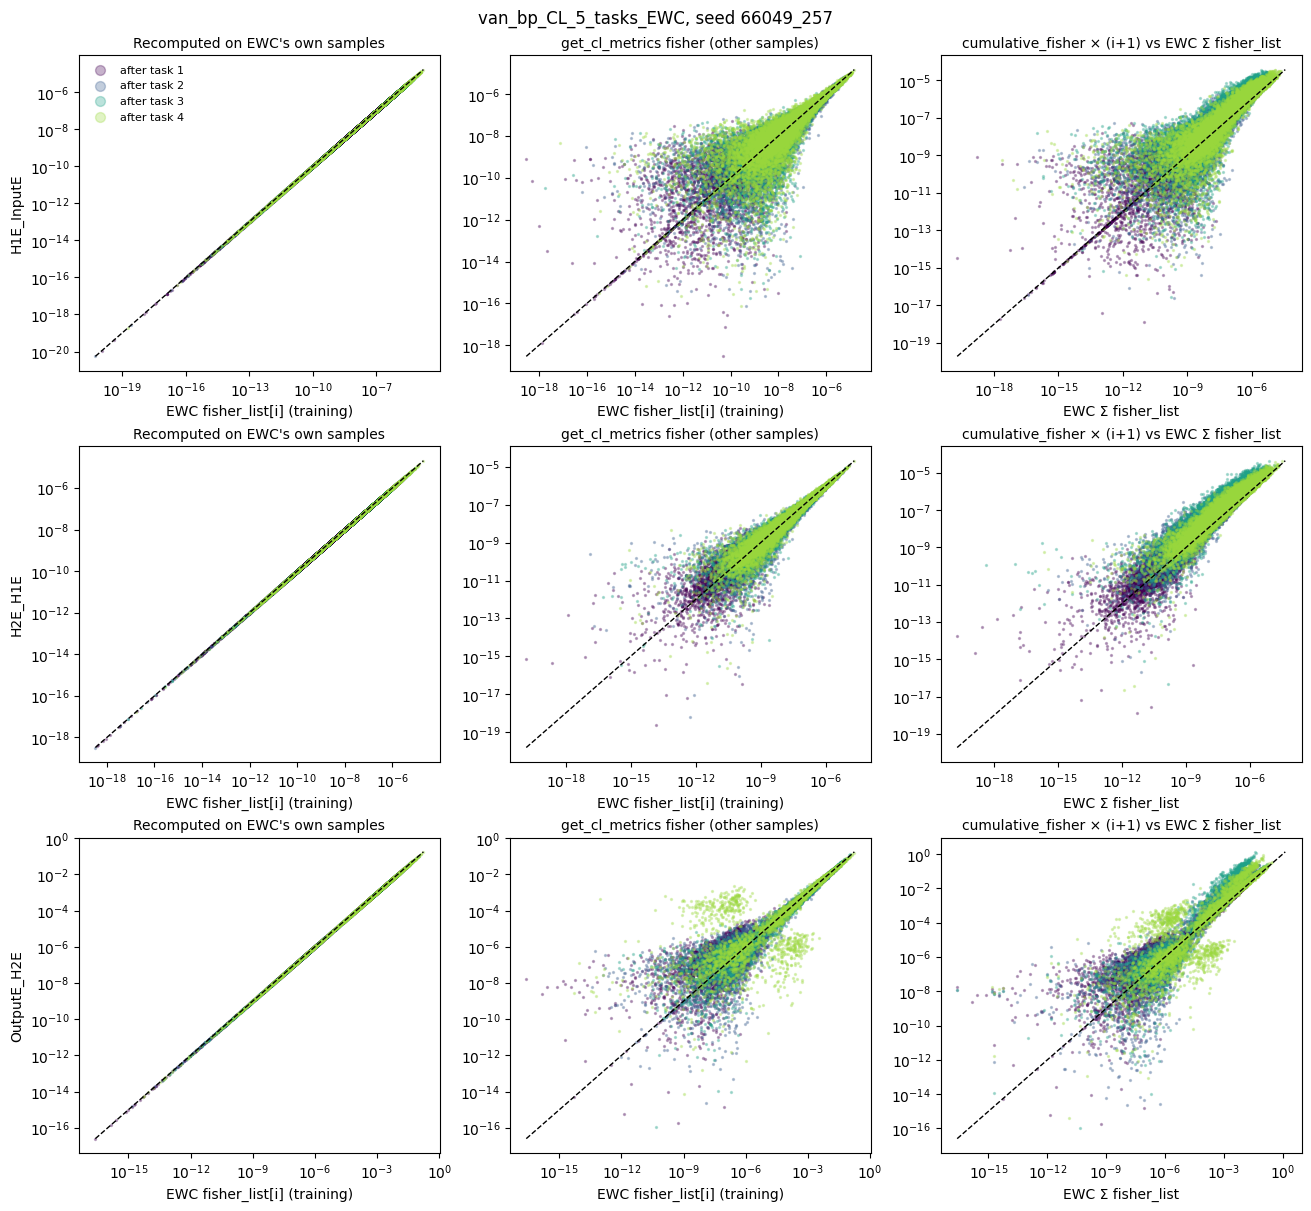

In [7]:
rows, pairs = [], {}
for name in projs:
    for i in range(num_tasks - 1):
        rule = nets[i + 1].projections[name].learning_rule
        F_rule = rule.fisher_list[i].numpy()
        F_sum_rule = sum(F.numpy() for F in rule.fisher_list[:i + 1])
        F_nb, F_cum_nb = saved[f'phase{i}']['fisher'][name], saved[f'phase{i}']['cumulative_fisher'][name] * (i + 1)
        pairs[name, i] = {'recomputed': (F_rule, recomputed[i][name]), 'per-task': (F_rule, F_nb),
                          'cumulative': (F_sum_rule, F_cum_nb)}
        ok, okc = (F_rule > 0) & (F_nb > 0), (F_sum_rule > 0) & (F_cum_nb > 0)
        rows.append({'projection': name, 'task': i + 1,
                     'per-task: sum ratio': F_nb.sum() / F_rule.sum(),
                     'per-task: spearman': spearmanr(F_rule[ok], F_nb[ok])[0],
                     'cumulative: sum ratio': F_cum_nb.sum() / F_sum_rule.sum(),
                     'cumulative: spearman': spearmanr(F_sum_rule[okc], F_cum_nb[okc])[0]})
display(pd.DataFrame(rows).set_index(['projection', 'task']).round(3))

colors = plt.cm.viridis(np.linspace(0, 0.85, num_tasks - 1))
titles = {'recomputed': "Recomputed on EWC's own samples", 'per-task': 'get_cl_metrics fisher (other samples)',
          'cumulative': 'cumulative_fisher × (i+1) vs EWC Σ fisher_list'}
fig, axes = plt.subplots(len(projs), 3, figsize=(13, 4 * len(projs)), squeeze=False, layout='constrained')
for row, name in zip(axes, projs):
    for ax, key in zip(row, titles):
        lo, hi = np.inf, -np.inf
        for i in range(num_tasks - 1):
            x, y = (a.ravel() for a in pairs[name, i][key])
            ok = np.flatnonzero((x > 0) & (y > 0))
            idx = rng.choice(ok, min(20000, len(ok)), replace=False)
            ax.scatter(x[idx], y[idx], s=2, alpha=0.3, color=colors[i], label=f'after task {i + 1}', rasterized=True)
            lo, hi = min(lo, x[idx].min(), y[idx].min()), max(hi, x[idx].max(), y[idx].max())
        ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(titles[key], fontsize=10)
        ax.set_xlabel('EWC Σ fisher_list' if key == 'cumulative' else 'EWC fisher_list[i] (training)')
    row[0].set_ylabel(name)
axes[0, 0].legend(markerscale=5, fontsize=8, frameon=False)
fig.suptitle(f'{model_key}, seed {seed}')
fig.savefig(f'{plot_dir}/ewc_fisher_vs_notebook_seed{seed}.png', dpi=110)
plt.show()

## 5. How strongly does the penalty constrain each layer?
With SGD, each step pulls a weight toward its anchor by the fraction $\text{lr} \cdot 2\lambda \sum_t F_t$ of its distance. Over a task of $T$ steps, weights with a pull ≪ $1/T$ are effectively unconstrained. The second table compares, at the end of each later task, the norm of the task-loss gradient with that of the penalty gradient, on 200 of that task's buffered samples. They are about equal where the penalty holds the weights in place.

In [8]:
net = nets[-1]
steps_per_task = net.ewc_buffer['num_seen']
rows = []
for name in projs:
    rule = net.projections[name].learning_rule
    pull = rule.learning_rate * 2 * rule.ewc_lambda * sum(F.numpy() for F in rule.fisher_list)
    rows.append({'projection': name, 'median pull/step': np.median(pull), '99th pct': np.percentile(pull, 99),
                 'max': pull.max(), f'% weights with pull > 1/{steps_per_task} steps':
                     100 * np.mean(pull > 1 / steps_per_task)})
display(pd.DataFrame(rows).set_index('projection'))

rows = []
for i in range(1, num_tasks):
    net = nets[i]
    data, target = buffer_tensors(net)
    weights = [net.projections[name].weight for name in projs]
    task_grad = [torch.zeros_like(w) for w in weights]
    for sample, sample_target in zip(data[:200], target[:200]):
        output = net.forward(sample)
        for total, grad in zip(task_grad, torch.autograd.grad(net.criterion(output, sample_target), weights)):
            total += grad / 200
    for name, w, grad in zip(projs, weights, task_grad):
        rule = net.projections[name].learning_rule
        penalty_grad = torch.autograd.grad(rule.ewc_lambda * rule.ewc_penalty(), w)[0]
        rows.append({'end of task': i + 1, 'projection': name, '|task grad|': grad.norm().item(),
                     '|penalty grad|': penalty_grad.norm().item(),
                     'task / penalty': (grad.norm() / penalty_grad.norm()).item()})
pd.DataFrame(rows).pivot(index='end of task', columns='projection', values='task / penalty').round(2)

,median pull/step,99th pct,max,% weights with pull > 1/4000 steps
projection,,,,
H1E_InputE,2.008217e-07,0.000019,0.000068,0.00
H2E_H1E,2.167424e-07,0.000012,0.000137,0.00
OutputE_H2E,1.059956e-03,0.272833,0.952470,57.82


projection,H1E_InputE,H2E_H1E,OutputE_H2E
end of task,,,
2,384.74,432.17,1.04
3,64.03,70.11,1.00
4,28.62,29.87,1.03
5,14.11,14.78,0.99


## Conclusions
- **The implementation is correct** (sections 1–3): bookkeeping, the stored Fisher (exact on recomputation, ≈ 1 against finite differences), the penalty gradient and the SGD step all match.
- **`get_cl_metrics` computes the same Fisher** (section 4). The per-task `fisher` agrees with EWC's up to sample noise. `cumulative_fisher` is larger by design, because it re-evaluates forgotten tasks at the current weights.
- **In this model EWC effectively constrains only the output layer** (section 5). One `ewc_lambda` is shared by all projections, and the hidden layers' Fisher is orders of magnitude smaller than the output layer's. So the hidden-layer pull is negligible: their task gradient is 10–500× the penalty gradient, while the output layer's is about 1×. This is why |ΔW| vs Fisher in the hidden layers looks like plain backprop. A separate λ per projection, or normalizing each projection's Fisher, would change that.